# Retail Sales Data Analysis 

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 

In [2]:
df = pd.read_csv("data.csv",encoding = "latin1")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [3]:
df.tail()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/2011 12:50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,12/9/2011 12:50,4.95,12680.0,France


In [4]:
df.shape

(541909, 8)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.3 MB


In [6]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [7]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [8]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

In [9]:
df= df.dropna(subset="Description")

In [10]:
df=df.dropna(subset="CustomerID")

In [11]:
df.isnull().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(5225)

In [13]:
df=df.drop_duplicates()

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
''' 
STEP 5 - Handle Cancelled Orders 
Important 

Agar InvoiceNo me C hai -> order cancelled hai 
'''

' \nSTEP 5 - Handle Cancelled Orders \nImportant \n\nAgar InvoiceNo me C hai -> order cancelled hai \n'

In [16]:
df = df[~df["InvoiceNo"].astype(str).str.contains("C")]
df.shape

(392732, 8)

In [17]:
# Create Revenue Column imp---

In [18]:
df["Revenue"]=df["Quantity"]*df["UnitPrice"]

In [19]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom,20.34


In [20]:
df.info()

<class 'pandas.DataFrame'>
Index: 392732 entries, 0 to 541908
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    392732 non-null  str    
 1   StockCode    392732 non-null  str    
 2   Description  392732 non-null  str    
 3   Quantity     392732 non-null  int64  
 4   InvoiceDate  392732 non-null  str    
 5   UnitPrice    392732 non-null  float64
 6   CustomerID   392732 non-null  float64
 7   Country      392732 non-null  str    
 8   Revenue      392732 non-null  float64
dtypes: float64(3), int64(1), str(5)
memory usage: 54.9 MB


In [21]:
# Convert Date Column 

In [22]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [23]:
df.info()

<class 'pandas.DataFrame'>
Index: 392732 entries, 0 to 541908
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    392732 non-null  str           
 1   StockCode    392732 non-null  str           
 2   Description  392732 non-null  str           
 3   Quantity     392732 non-null  int64         
 4   InvoiceDate  392732 non-null  datetime64[us]
 5   UnitPrice    392732 non-null  float64       
 6   CustomerID   392732 non-null  float64       
 7   Country      392732 non-null  str           
 8   Revenue      392732 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(1), str(4)
memory usage: 49.2 MB


In [24]:
# Feature Engineering, Create Month Column 

In [25]:
df["Month"] = df["InvoiceDate"].dt.month

In [26]:
# Create Year Column 

In [27]:
df["Year"] = df["InvoiceDate"].dt.year

In [28]:
df["Day"] = df["InvoiceDate"].dt.day_name()

In [29]:
# Exploratory Data Analysis (EDA)
#1. Total Revenue 

In [30]:
total_revenue = df["Revenue"].sum()
print(total_revenue)

8887208.894


In [31]:
#2. Top 10 Products 

In [32]:
top_products = df.groupby("Description")["Revenue"].sum().sort_values(ascending = False).head(10)
top_products

Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142264.75
WHITE HANGING HEART T-LIGHT HOLDER    100392.10
JUMBO BAG RED RETROSPOT                85040.54
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
POSTAGE                                77803.96
PARTY BUNTING                          68785.23
ASSORTED COLOUR BIRD ORNAMENT          56413.03
Manual                                 53419.93
RABBIT NIGHT LIGHT                     51251.24
Name: Revenue, dtype: float64

In [33]:
#3. Top 10 Countries

In [64]:
top_countrys = df.groupby("Country")["Revenue"].sum().sort_values(ascending = False).head(10)
top_countrys

Country
United Kingdom    7285024.644
Netherlands        285446.340
EIRE               265262.460
Germany            228678.400
France             208934.310
Australia          138453.810
Spain               61558.560
Switzerland         56443.950
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64

In [35]:
#4. Monthly Sales 

In [36]:
monthly_sales = df.groupby("Month")["Revenue"].sum()
monthly_sales

Month
1      568101.310
2      446084.920
3      594081.760
4      468374.331
5      677355.150
6      660046.050
7      598962.901
8      644051.040
9      950690.202
10    1035642.450
11    1156205.610
12    1087613.170
Name: Revenue, dtype: float64

In [57]:
Daily_sales = df.groupby("Day")["Revenue"].sum()
Daily_sales

Day
Friday       1483080.811
Monday       1363604.401
Sunday        785490.321
Thursday     1973015.730
Tuesday      1697733.801
Wednesday    1584283.830
Name: Revenue, dtype: float64

In [38]:
yearly_sales = df.groupby("Year")["Revenue"].sum()
yearly_sales

Year
2010     570422.730
2011    8316786.164
Name: Revenue, dtype: float64

In [42]:
# Repeted Customer
repeated_customers = df["CustomerID"].value_counts()
print(repeated_customers)

CustomerID
17841.0    7676
14911.0    5672
14096.0    5111
12748.0    4413
14606.0    2677
           ... 
18184.0       1
13256.0       1
13017.0       1
18174.0       1
15195.0       1
Name: count, Length: 4339, dtype: int64


In [43]:
# find those customers who have placed more then 1000 orders 

In [45]:
repeated_customers_greater_1000 = df["CustomerID"].value_counts()>=1000
print(repeated_customers_greater_1000)

CustomerID
17841.0     True
14911.0     True
14096.0     True
12748.0     True
14606.0     True
           ...  
18184.0    False
13256.0    False
13017.0    False
18174.0    False
15195.0    False
Name: count, Length: 4339, dtype: bool


In [47]:
repeated_customers = df.groupby("CustomerID")["CustomerID"].count().sort_values(ascending = False).head(20)
print(repeated_customers)

CustomerID
17841.0    7676
14911.0    5672
14096.0    5111
12748.0    4413
14606.0    2677
15311.0    2366
14646.0    2080
13089.0    1814
13263.0    1667
14298.0    1637
15039.0    1477
14156.0    1395
18118.0    1263
14159.0    1175
14796.0    1132
16033.0    1128
15005.0    1112
14056.0    1088
14769.0    1062
13081.0    1028
Name: CustomerID, dtype: int64


# Data Visualization

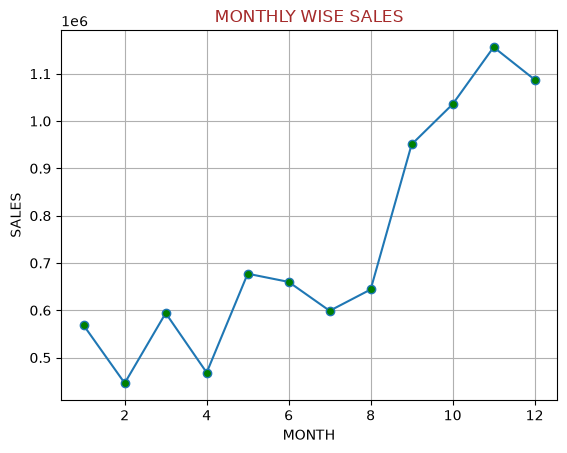

In [49]:
plt.plot(monthly_sales.index,monthly_sales.values,marker = 'o',markerfacecolor = "green")
plt.grid()
plt.title("MONTHLY WISE SALES",color = "brown")
plt.xlabel("MONTH")
plt.ylabel("SALES")
plt.show()

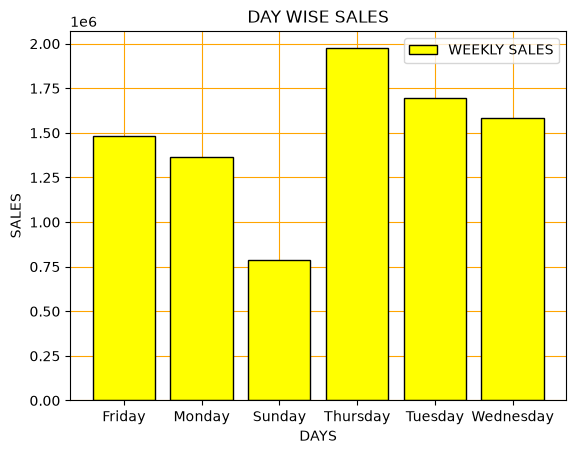

In [62]:
plt.bar(Daily_sales.index , Daily_sales.values , color = "yellow", edgecolor = "black",label = "WEEKLY SALES", zorder = 2)
plt.title("DAY WISE SALES")
plt.xlabel("DAYS")
plt.ylabel("SALES")
plt.legend()
plt.grid(color = "orange")
plt.show()

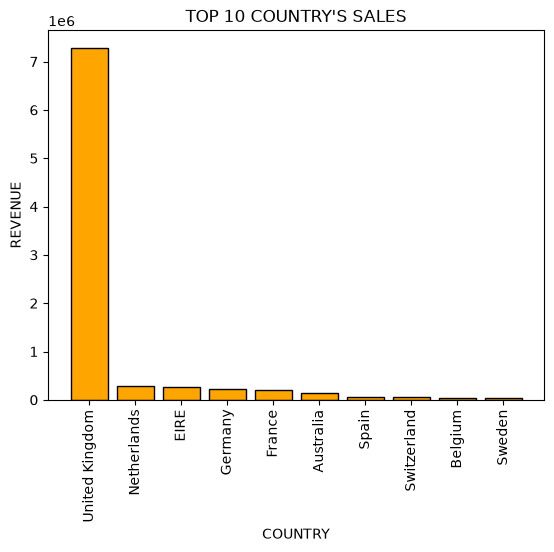

In [68]:
plt.bar(top_countrys.index,top_countrys.values,color = "orange",edgecolor = "black")
plt.xticks(rotation = 90)
plt.xlabel("COUNTRY")
plt.ylabel("REVENUE")
plt.title("TOP 10 COUNTRY'S SALES")
plt.show()

In [ ]:
# Top Products Bar

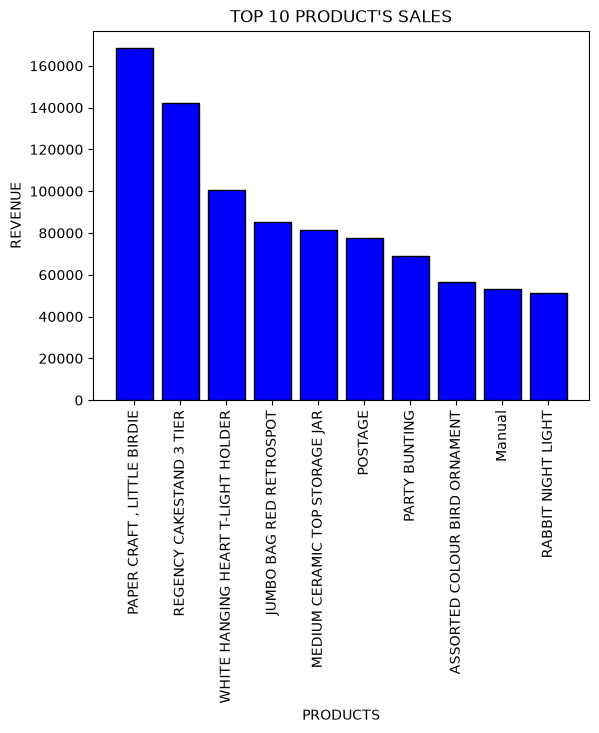

In [69]:
plt.bar(top_products.index,top_products.values,color = "blue",edgecolor = "black")
plt.xticks(rotation = 90)
plt.xlabel("PRODUCTS")
plt.ylabel("REVENUE")
plt.title("TOP 10 PRODUCT'S SALES")
plt.show()

In [ ]:
'''
BUSINESS INSIGHTS--->

United Kingdom generated highest revenue.
November had Highest Sales.
Few Customers contributed major revenue.
Cretain products dominate total sales,
Weekend 